<a href="https://colab.research.google.com/github/herr-hollis/Data-driven-Classification-Of-Gamma-ray-Bursts-Using-Duration-Hardness-And-Spectral-Peak-Energy/blob/main/Data_Driven_Classification_of_Gamma_Ray_Bursts_Using_Duration%2C_Hardness_and_Spectral_Peak_Energy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q hdbscan umap-learn astropy openpyxl #Install packages

## 1. Imports and settings

In [2]:
import os, sys, json, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from astropy.io import fits
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
import hdbscan, umap
warnings.filterwarnings('ignore')

IN_COLAB = 'google.colab' in sys.modules
OUT = 'grb_outputs'; os.makedirs(OUT, exist_ok=True)

# Bootstrap replicates for the k=2 vs k=3 likelihood-ratio test.
# Poster used 200 (1D) and 100 (2D). Lower these for a quick run.
N_BOOT_1D = int(os.environ.get('N_BOOT_1D', 200))
N_BOOT_2D = int(os.environ.get('N_BOOT_2D', 100))

# Poster colours
RED, BLUE, NAVY = '#e8504f', '#2f7de0', '#1f2a5c'   # red = short-like, blue = long-like

trapz = getattr(np, 'trapezoid', None) or np.trapz   # works with NumPy 1.x and 2.x

def GM(k, **kw):
    # Gaussian mixture with strict convergence (sklearn's default tol stops too early for n ~ 4000)
    kw.setdefault('n_init', 10)
    return GaussianMixture(k, tol=1e-7, max_iter=1500, reg_covar=1e-6, init_params='k-means++', **kw)

## 2. Load the Fermi GBM catalog

In [3]:
if IN_COLAB:
    from google.colab import files
    up = files.upload()                       # choose browse_results.fits
    FITS_PATH = [f for f in up if f.lower().endswith(('.fits', '.fit', '.fits.gz'))][0]
else:
    FITS_PATH = os.environ.get('GRB_FITS', 'browse_results.fits')

COLS = ['NAME', 'T90', 'T90_ERROR', 'FLNC_BEST_FITTING_MODEL',
        'FLNC_BAND_EPEAK', 'FLNC_BAND_EPEAK_POS_ERR', 'FLNC_BAND_EPEAK_NEG_ERR', 'FLNC_BAND_ALPHA', 'FLNC_BAND_BETA',
        'FLNC_COMP_EPEAK', 'FLNC_COMP_EPEAK_POS_ERR', 'FLNC_COMP_EPEAK_NEG_ERR', 'FLNC_COMP_INDEX', 'FLNC_PLAW_INDEX']

data = fits.open(FITS_PATH)[1].data
cols_upper = {c.upper(): c for c in data.columns.names}
missing = [c for c in COLS if c not in cols_upper]
assert not missing, f'FITS file is missing columns: {missing}'
raw = {}
for c in COLS:
    a = np.array(data[cols_upper[c]])
    raw[c] = a.astype(float) if a.dtype.kind in 'fi' else np.char.strip(a.astype(str))
df = pd.DataFrame(raw)
df['model'] = df.FLNC_BEST_FITTING_MODEL
print('Bursts in catalog:', len(df))

Saving browse_results.fits to browse_results (1).fits
Bursts in catalog: 4415


## 3. Features: T90, hardness ratio (Eq. 1) and E_peak

$$\mathrm{HR}=\frac{\int_{50}^{300}E\,N(E)\,dE}{\int_{10}^{50}E\,N(E)\,dE}$$

HR is computed from each burst's best-fitting time-integrated spectral model (Band, Comptonised or power law).
E_peak is kept only for Band/Comptonised fits with 10 < E_peak < 10,000 keV and relative error < 100%.

In [4]:
E_LO, E_HI = np.geomspace(10, 50, 300), np.geomspace(50, 300, 300)

def band_N(E, alpha, beta, ep):
    e0 = ep / (2 + alpha); eb = (alpha - beta) * e0
    low = E**alpha * np.exp(-E / e0)
    high = eb**(alpha - beta) * np.exp(beta - alpha) * E**beta
    return np.where(E < eb, low, high)

def energy_flux(kind, p, E):
    if kind == 'comp':   idx, ep = p; N = E**idx * np.exp(-(idx + 2) * E / ep)
    elif kind == 'band': a, b, ep = p; N = band_N(E, a, b, ep)
    else:                idx, = p; N = E**idx
    return trapz(E * N, E)          # amplitude cancels in the ratio

def hardness(r):
    m = r.model
    try:
        if m == 'flnc_comp' and np.isfinite(r.FLNC_COMP_EPEAK) and r.FLNC_COMP_EPEAK > 0 and r.FLNC_COMP_INDEX > -2:
            k, p = 'comp', (r.FLNC_COMP_INDEX, r.FLNC_COMP_EPEAK)
        elif m == 'flnc_band' and r.FLNC_BAND_ALPHA > -2 and r.FLNC_BAND_BETA < r.FLNC_BAND_ALPHA and r.FLNC_BAND_EPEAK > 0:
            k, p = 'band', (r.FLNC_BAND_ALPHA, r.FLNC_BAND_BETA, r.FLNC_BAND_EPEAK)
        elif m == 'flnc_plaw' and np.isfinite(r.FLNC_PLAW_INDEX):
            k, p = 'plaw', (r.FLNC_PLAW_INDEX,)
        else:
            return np.nan
        hr = energy_flux(k, p, E_HI) / energy_flux(k, p, E_LO)
        return hr if np.isfinite(hr) and hr > 0 else np.nan
    except Exception:
        return np.nan

df['HR'] = [hardness(r) for r in df.itertuples()]
df['ok_base'] = (df.T90 > 0) & np.isfinite(df.T90) & np.isfinite(df.HR)
df['logT90'] = np.log10(df.T90.where(df.ok_base))
df['logHR'] = np.log10(df.HR.where(df.ok_base))

ep, pe, ne = (np.full(len(df), np.nan) for _ in range(3))
b = (df.model == 'flnc_band').values; c = (df.model == 'flnc_comp').values
ep[b], pe[b], ne[b] = df.FLNC_BAND_EPEAK[b], df.FLNC_BAND_EPEAK_POS_ERR[b], df.FLNC_BAND_EPEAK_NEG_ERR[b]
ep[c], pe[c], ne[c] = df.FLNC_COMP_EPEAK[c], df.FLNC_COMP_EPEAK_POS_ERR[c], df.FLNC_COMP_EPEAK_NEG_ERR[c]
df['Epeak'] = ep
df['Epeak_relerr'] = (np.abs(pe) + np.abs(ne)) / 2 / ep
df['ok_epeak'] = df.ok_base & np.isfinite(ep) & (ep > 10) & (ep < 10000) & (df.Epeak_relerr < 1.0)
df['logEpeak'] = np.log10(df.Epeak.where(df.ok_epeak))

A = df[df.ok_base].copy()     # sample A: T90 + HR
B = df[df.ok_epeak].copy()    # sample B: T90 + HR + Epeak
print(f'Sample A (T90, HR):        {len(A)} bursts')
print(f'Sample B (T90, HR, Epeak): {len(B)} bursts')

Sample A (T90, HR):        3759 bursts
Sample B (T90, HR, Epeak): 2933 bursts


## 4. Gaussian mixture model (Eq. 2) and BIC (Eq. 3)

$$p(\mathbf z)=\sum_{k=1}^{K}\pi_k\,\mathcal N(\mathbf z\mid\boldsymbol\mu_k,\boldsymbol\Sigma_k),\qquad \mathrm{BIC}=-2\ln\hat L+q\ln n$$

In [5]:
def bic_scan(X, kmax=6):
    return {k: float(GM(k, n_init=20, random_state=0).fit(X).bic(X)) for k in range(1, kmax + 1)}

X1 = A[['logT90']].values                                   # 1D: duration only
sc2 = StandardScaler().fit(A[['logT90', 'logHR']]);  X2 = sc2.transform(A[['logT90', 'logHR']])
sc3 = StandardScaler().fit(B[['logT90', 'logHR', 'logEpeak']]); X3 = sc3.transform(B[['logT90', 'logHR', 'logEpeak']])

res = {'bic_1d': bic_scan(X1, 5), 'bic_2d': bic_scan(X2), 'bic_3d': bic_scan(X3)}
for key in res:
    d = res[key]; print(f'{key}: best k = {min(d, key=d.get)} | BIC - BIC(k=2):',
                        {k: round(v - d[2], 1) for k, v in d.items()})

bic_1d: best k = 2 | BIC - BIC(k=2): {1: 858.7, 2: 0.0, 3: 14.5, 4: 38.5, 5: 61.1}
bic_2d: best k = 4 | BIC - BIC(k=2): {1: 1136.7, 2: 0.0, 3: -7.9, 4: -19.8, 5: -10.6, 6: 17.0}
bic_3d: best k = 6 | BIC - BIC(k=2): {1: 2030.5, 2: 0.0, 3: -469.8, 4: -674.9, 5: -768.2, 6: -826.8}


In [6]:
# 1D two-class fit: medians and weights of the short and long components (Fig. 1)
g1 = GM(2, random_state=0).fit(X1); o = np.argsort(g1.means_.ravel())
for name, i in (('short', o[0]), ('long', o[1])):
    print(f'{name}: median T90 = {10**g1.means_.ravel()[i]:.2f} s, weight = {g1.weights_[i]*100:.1f}%')
xb = brentq(lambda x: g1.predict_proba([[x]])[0][o[0]] - 0.5, g1.means_.ravel()[o[0]], g1.means_.ravel()[o[1]])
print(f'Equal-probability boundary: T90 = {10**xb:.2f} s')

def fit_ordered(X, d, k):
    # Fit a k-component GMM and relabel so cluster 0 has the shortest median T90
    g = GM(k, random_state=0).fit(X); lab = g.predict(X)
    order = np.argsort([np.median(d.T90.values[lab == i]) for i in range(k)])
    remap = {old: new for new, old in enumerate(order)}
    return np.array([remap[l] for l in lab])

A['gmm2'] = fit_ordered(X2, A, 2); A['gmm3'] = fit_ordered(X2, A, 3)
B['gmm2'] = fit_ordered(X3, B, 2); B['gmm3'] = fit_ordered(X3, B, 3)

agree = ((A.gmm2 == 0) == (A.T90 < 2)).mean()
hr_ratio = A.HR[A.gmm2 == 0].median() / A.HR[A.gmm2 == 1].median()
print(f'\n2-class GMM (T90, HR) agrees with the 2 s cut for {agree*100:.1f}% of bursts')
print(f'Short-like bursts are {hr_ratio:.1f}x harder (median HR ratio)')
print('\n3-class GMM on (T90, HR, Epeak), sample B:')
print(B.groupby('gmm3').agg(n=('NAME', 'size'), median_T90=('T90', 'median'),
                            median_HR=('HR', 'median'), median_Epeak_keV=('Epeak', 'median')).round(2))

short: median T90 = 0.83 s, weight = 20.3%
long: median T90 = 25.93 s, weight = 79.7%
Equal-probability boundary: T90 = 3.12 s

2-class GMM (T90, HR) agrees with the 2 s cut for 97.5% of bursts
Short-like bursts are 2.5x harder (median HR ratio)

3-class GMM on (T90, HR, Epeak), sample B:
         n  median_T90  median_HR  median_Epeak_keV
gmm3                                               
0      584        1.07       8.49            744.90
1     1017       18.94       1.98            104.29
2     1332       37.12       3.68            234.78


## 5. Is there a third class? Parametric bootstrap likelihood-ratio test

Null hypothesis: the data come from the fitted 2-component model. Simulate from it, refit k = 2 and k = 3, and compare.
This is the slowest step (several minutes with the default replicates).

In [7]:
def lrt(X, nrep, seed0=1000):
    a = GM(2, n_init=5, random_state=0).fit(X); b = GM(3, n_init=5, random_state=0).fit(X)
    obs = 2 * len(X) * (b.score(X) - a.score(X)); null = []
    for i in range(nrep):
        Xs = a.sample(len(X))[0]
        p = GM(2, n_init=3, random_state=seed0 + i).fit(Xs); q = GM(3, n_init=3, random_state=seed0 + i).fit(Xs)
        null.append(2 * len(Xs) * (q.score(Xs) - p.score(Xs)))
    null = np.array(null)
    return {'Lambda_obs': round(float(obs), 1), 'replicates': nrep,
            'p_value': float(((null >= obs).sum() + 1) / (nrep + 1)), 'null_95th': round(float(np.percentile(null, 95)), 1)}

t0 = time.time()
res['lrt_1d'] = lrt(X1, N_BOOT_1D); print('1D (T90):     ', res['lrt_1d'])
res['lrt_2d'] = lrt(X2, N_BOOT_2D); print('2D (T90, HR): ', res['lrt_2d'])
print(f'({time.time()-t0:.0f} s)')

1D (T90):      {'Lambda_obs': 9.9, 'replicates': 200, 'p_value': 0.004975124378109453, 'null_95th': 2.2}
2D (T90, HR):  {'Lambda_obs': 55.2, 'replicates': 100, 'p_value': 0.009900990099009901, 'null_95th': 12.3}
(1391 s)


## 6. Density clustering: HDBSCAN and UMAP (10 random seeds)

In [8]:
B['hdb'] = hdbscan.HDBSCAN(min_cluster_size=60, min_samples=10).fit(X3).labels_
print('HDBSCAN on the 3 features, cluster sizes (-1 = unassigned):', B.hdb.value_counts().to_dict())

emb = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42).fit_transform(X3)
B['u1'], B['u2'] = emb[:, 0], emb[:, 1]
lab = hdbscan.HDBSCAN(min_cluster_size=60, min_samples=10).fit(emb).labels_
# name clusters: lowest median T90 -> 0 (short-like)
cl = sorted(set(lab) - {-1}, key=lambda c: np.median(B.T90.values[lab == c]))
B['hdb_umap'] = [cl.index(l) if l in cl else -1 for l in lab]
print('UMAP + HDBSCAN cluster sizes:', B.hdb_umap.value_counts().to_dict())

nclus = []
for seed in range(10):
    e = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=seed).fit_transform(X3)
    nclus.append(len(set(hdbscan.HDBSCAN(min_cluster_size=60, min_samples=10).fit(e).labels_) - {-1}))
print('Clusters found for UMAP seeds 0-9:', nclus)
print('ARI (2-class GMM vs UMAP+HDBSCAN):', round(adjusted_rand_score(B.gmm2, B.hdb_umap), 3))

HDBSCAN on the 3 features, cluster sizes (-1 = unassigned): {0: 2237, -1: 583, 1: 113}
UMAP + HDBSCAN cluster sizes: {1: 2466, 0: 420, -1: 47}
Clusters found for UMAP seeds 0-9: [2, 2, 2, 2, 11, 2, 2, 2, 2, 2]
ARI (2-class GMM vs UMAP+HDBSCAN): 0.334


## 7. Validation: bursts with known progenitors (Table 1)

In [9]:
KNOWN = {'GRB090510016': ('GRB 090510', 'merger'), 'GRB170817529': ('GRB 170817A', 'merger'),
         'GRB200826187': ('GRB 200826A', 'collapsar'), 'GRB211211549': ('GRB 211211A', 'merger'),
         'GRB130427324': ('GRB 130427A', 'collapsar')}
name2 = {0: 'short', 1: 'long'}; umapname = {0: 'short', 1: 'long', -1: 'unassigned'}
rows = []
for n, (label, origin) in KNOWN.items():
    a = A[A.NAME == n]; b = B[B.NAME == n]
    expected = 'short' if origin == 'merger' else 'long'
    g = name2[int(a.gmm2.iloc[0])] if len(a) else '-'
    u = umapname[int(b.hdb_umap.iloc[0])] if len(b) else '-'
    rows.append({'GRB': label, 'Origin': origin, 'T90 (s)': round(float(a.T90.iloc[0]), 2) if len(a) else None,
                 'GMM': g + (' ✓' if g == expected else ' ✗' if g != '-' else ''),
                 'UMAP': u + (' ✓' if u == expected else ' ✗' if u != '-' else '')})
table1 = pd.DataFrame(rows); table1

,GRB,Origin,T90 (s),GMM,UMAP
0,GRB 090510,merger,0.96,short ✓,short ✓
1,GRB 170817A,merger,2.05,short ✓,-
2,GRB 200826A,collapsar,1.14,short ✗,long ✓
3,GRB 211211A,merger,34.30,long ✗,long ✗
4,GRB 130427A,collapsar,138.24,long ✓,long ✓


## 8. Figures 1–4

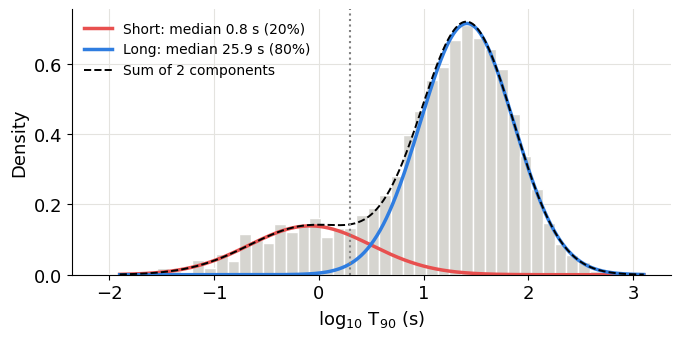

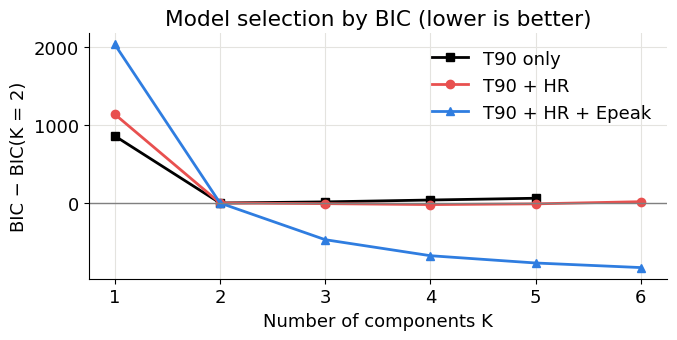

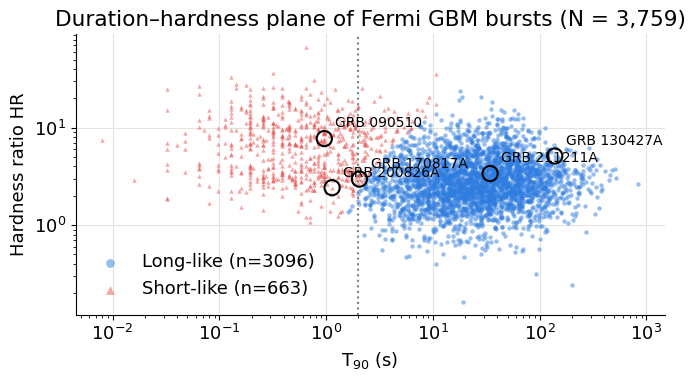

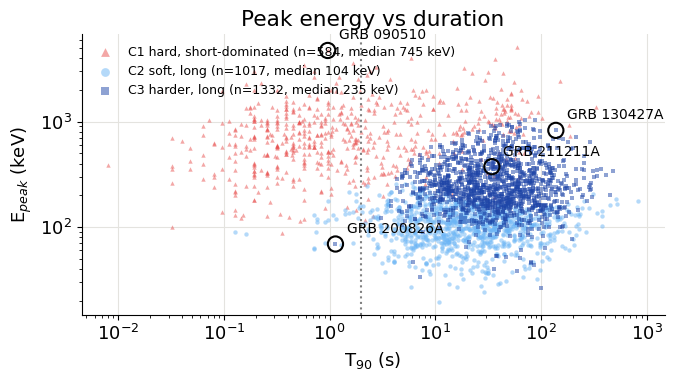

In [10]:
plt.rcParams.update({'font.size': 13, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True, 'legend.frameon': False})
LABELS = {n: v[0] for n, v in KNOWN.items()}

def annotate(ax, d, x, y):
    for n, lab in LABELS.items():
        r = d[d.NAME == n]
        if r.empty: continue
        r = r.iloc[0]
        ax.scatter(r[x], r[y], s=120, facecolor='none', edgecolor='k', lw=1.5, zorder=5)
        ax.annotate(lab, (r[x], r[y]), xytext=(8, 8), textcoords='offset points', fontsize=10)

# Fig 1: duration distribution + 2-class GMM
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(X1.ravel(), bins=45, density=True, color='#d6d5d0', edgecolor='white')
xs = np.linspace(-1.9, 3.1, 500); tot = np.zeros_like(xs)
for name, i, col in (('Short', o[0], RED), ('Long', o[1], BLUE)):
    y = g1.weights_[i] * norm.pdf(xs, g1.means_.ravel()[i], np.sqrt(g1.covariances_.ravel()[i])); tot += y
    ax.plot(xs, y, color=col, lw=2.5, label=f'{name}: median {10**g1.means_.ravel()[i]:.1f} s ({g1.weights_[i]*100:.0f}%)')
ax.plot(xs, tot, 'k--', lw=1.4, label='Sum of 2 components')
ax.axvline(np.log10(2), color='grey', ls=':'); ax.set_xlabel(r'log$_{10}$ T$_{90}$ (s)'); ax.set_ylabel('Density')
ax.legend(loc='upper left', fontsize=10); fig.tight_layout(); fig.savefig(f'{OUT}/fig1_t90.png', dpi=200); plt.show()

# Fig 2: BIC relative to k = 2
fig, ax = plt.subplots(figsize=(7, 3.6))
for key, lab, col, m in (('bic_1d', 'T90 only', 'k', 's'), ('bic_2d', 'T90 + HR', RED, 'o'), ('bic_3d', 'T90 + HR + Epeak', BLUE, '^')):
    d = res[key]; ks = sorted(d); ax.plot(ks, [d[k] - d[2] for k in ks], marker=m, color=col, lw=2, label=lab)
ax.axhline(0, color='grey', lw=1); ax.set_xlabel('Number of components K'); ax.set_ylabel('BIC − BIC(K = 2)')
ax.set_title('Model selection by BIC (lower is better)'); ax.legend(); fig.tight_layout()
fig.savefig(f'{OUT}/fig2_bic.png', dpi=200); plt.show()

# Fig 3: hardness vs duration, 2-class GMM
fig, ax = plt.subplots(figsize=(7, 4))
for k, col, m, lab in ((1, BLUE, 'o', 'Long-like'), (0, RED, '^', 'Short-like')):
    s = A[A.gmm2 == k]; ax.scatter(s.T90, s.HR, s=10, c=col, marker=m, alpha=0.5, lw=0, label=f'{lab} (n={len(s)})')
ax.set_xscale('log'); ax.set_yscale('log'); ax.axvline(2, color='grey', ls=':')
annotate(ax, A, 'T90', 'HR'); ax.set_xlabel('T$_{90}$ (s)'); ax.set_ylabel('Hardness ratio HR')
ax.set_title(f'Duration–hardness plane of Fermi GBM bursts (N = {len(A):,})'); ax.legend(markerscale=2)
fig.tight_layout(); fig.savefig(f'{OUT}/fig3_hardness.png', dpi=200); plt.show()

# Fig 4: Epeak vs duration, 3-class GMM
fig, ax = plt.subplots(figsize=(7, 4))
names3 = {0: 'C1 hard, short-dominated', 1: 'C2 soft, long', 2: 'C3 harder, long'}
cols3 = {0: (RED, '^'), 1: ('#6bb5f5', 'o'), 2: ('#1f46a8', 's')}
for k in (0, 1, 2):
    s = B[B.gmm3 == k]; col, m = cols3[k]
    ax.scatter(s.T90, s.Epeak, s=10, c=col, marker=m, alpha=0.5, lw=0,
               label=f'{names3[k]} (n={len(s)}, median {s.Epeak.median():.0f} keV)')
ax.set_xscale('log'); ax.set_yscale('log'); ax.axvline(2, color='grey', ls=':')
annotate(ax, B, 'T90', 'Epeak'); ax.set_xlabel('T$_{90}$ (s)'); ax.set_ylabel('E$_{peak}$ (keV)')
ax.set_title('Peak energy vs duration'); ax.legend(markerscale=2, fontsize=9)
fig.tight_layout(); fig.savefig(f'{OUT}/fig4_epeak.png', dpi=200); plt.show()

## 9. Export data (CSV + Excel for Origin) and download

In [11]:
dA = pd.DataFrame({'Burst': A.NAME, 'T90_s': A.T90, 'log10_T90': A.logT90, 'HR': A.HR, 'log10_HR': A.logHR,
                   'GMM2_cluster': A.gmm2.map({0: 'short-like', 1: 'long-like'}),
                   'GMM3_cluster': A.gmm3.map({0: 'short-like', 1: 'intermediate', 2: 'long-like'})}).sort_values('T90_s')
dB = pd.DataFrame({'Burst': B.NAME, 'T90_s': B.T90, 'log10_T90': B.logT90, 'HR': B.HR, 'log10_HR': B.logHR,
                   'Epeak_keV': B.Epeak, 'log10_Epeak': B.logEpeak,
                   'GMM3_cluster': B.gmm3.map(names3), 'UMAP1': B.u1, 'UMAP2': B.u2,
                   'UMAP_HDBSCAN': B.hdb_umap.map({-1: 'unassigned', 0: 'short-like', 1: 'long-like'})}).sort_values('T90_s')
bic = pd.DataFrame({'K': range(1, 7)})
for key, lab in (('bic_1d', 'T90'), ('bic_2d', 'T90+HR'), ('bic_3d', 'T90+HR+Epeak')):
    bic[f'BIC_minus_BIC2_{lab}'] = [res[key][k] - res[key][2] if k in res[key] else np.nan for k in bic.K]

dA.to_csv(f'{OUT}/Data_T90_HR.csv', index=False); dB.to_csv(f'{OUT}/Data_T90_HR_Epeak.csv', index=False)
with pd.ExcelWriter(f'{OUT}/GRB_data_for_Origin.xlsx') as w:
    dA.to_excel(w, sheet_name='Data_T90_HR', index=False)
    dB.to_excel(w, sheet_name='Data_T90_HR_Epeak', index=False)
    bic.to_excel(w, sheet_name='Fig2_BIC', index=False)
    table1.to_excel(w, sheet_name='Table1_known', index=False)
json.dump(res, open(f'{OUT}/results.json', 'w'), indent=1, default=float)
print('Saved:', sorted(os.listdir(OUT)))

if IN_COLAB:
    import shutil; shutil.make_archive('grb_outputs', 'zip', OUT); files.download('grb_outputs.zip')

Saved: ['Data_T90_HR.csv', 'Data_T90_HR_Epeak.csv', 'GRB_data_for_Origin.xlsx', 'fig1_t90.png', 'fig2_bic.png', 'fig3_hardness.png', 'fig4_epeak.png', 'results.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>